## Regresion: Diabetes

Vamos a implementar un ejemplo completo de regresión lineal múltiple utilizando el dataset Diabetes de scikit-learn.
El objetivo es predecir una medida cuantitativa de la progresión de la diabetes a partir de diez variables clínicas basales. Es un dataset educativo de 442 registros y diez características numéricas.
Importante: la variable objetivo representa una medida cuantitativa de progresión de la enfermedad, no un diagnóstico de diabetes ni una predicción directa de glucosa en sangre.

Cantidad de registros: 442
Cantidad de variables: 10

Primeros registros:
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  
0 -0.002592  0.019907 -0.017646  
1 -0.039493 -0.068332 -0.092204  
2 -0.002592  0.002861 -0.025930  
3  0.034309  0.022688 -0.009362  
4 -0.002592 -0.031988 -0.046641  

Variable objetivo:
0    151.0
1     75.0
2    141.0
3    206.0
4    135.0
Name: target, dtype: float64

--- Evaluación del modelo ---
MAE:  42.79
RMSE: 53.85
R²:   0.4526

Coeficientes del modelo:
  Variable  Coeficiente
8       s5   736.198859
2      bmi   542.428759
5

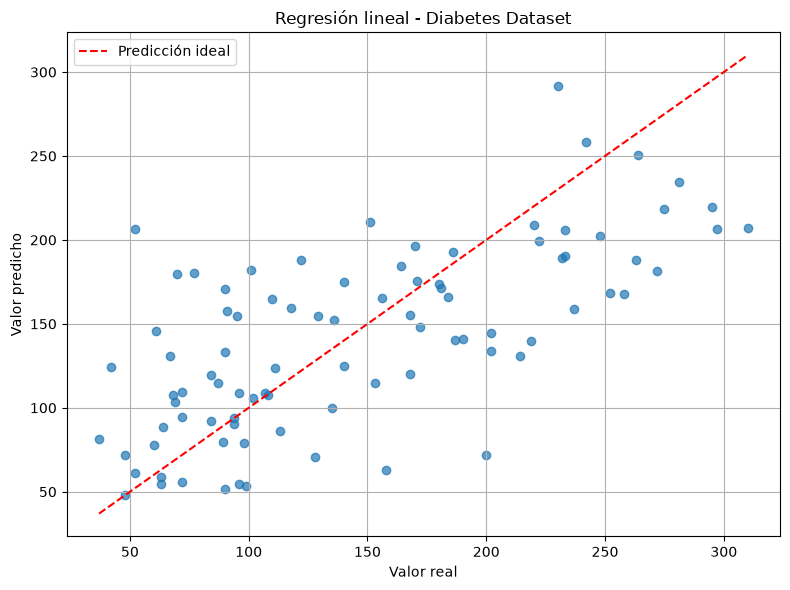


--- Ejemplo de predicción ---
Valor real:      219.00
Valor predicho:  139.55
Error absoluto:  79.45


: 

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Cargar el dataset
diabetes = load_diabetes(as_frame=True)

X = diabetes.data
y = diabetes.target

print("Cantidad de registros:", X.shape[0])
print("Cantidad de variables:", X.shape[1])

print("\nPrimeros registros:")
print(X.head())

print("\nVariable objetivo:")
print(y.head())

# 2. Dividir datos en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# 3. Crear y entrenar el modelo
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# 4. Realizar predicciones
y_pred = modelo.predict(X_test)

# 5. Evaluar el modelo
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

print("\n--- Evaluación del modelo ---")
print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²:   {r2:.4f}")

# 6. Mostrar los coeficientes aprendidos
coeficientes = pd.DataFrame({
    "Variable": X.columns,
    "Coeficiente": modelo.coef_
})

print("\nCoeficientes del modelo:")
print(coeficientes.sort_values(
    by="Coeficiente",
    ascending=False
))

print(f"\nIntercepto: {modelo.intercept_:.2f}")

# 7. Comparar valores reales y predichos
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

limite_min = min(y_test.min(), y_pred.min())
limite_max = max(y_test.max(), y_pred.max())

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    "r--",
    label="Predicción ideal"
)

plt.xlabel("Valor real")
plt.ylabel("Valor predicho")
plt.title("Regresión lineal - Diabetes Dataset")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 8. Predecir usando un registro del conjunto de prueba
muestra = X_test.iloc[[0]]
prediccion = modelo.predict(muestra)[0]
valor_real = y_test.iloc[0]

print("\n--- Ejemplo de predicción ---")
print(f"Valor real:      {valor_real:.2f}")
print(f"Valor predicho:  {prediccion:.2f}")
print(f"Error absoluto:  {abs(valor_real - prediccion):.2f}")
